# Example DAQReader plugin

In this notebook we show an example of a dummy DAQReader for a triggered DAQ system. The example data is stored in `abstrax/test_data/dummy_binary_files`. Next to the binary files, which are named `wf_0000X.bin`, the DAQ in this example also writes a config file and a metadata file. Of course, this depends on the exact setup you are using.

In this example the DAQ is externally triggered and records both enabled channels (channel 0 and 1) for a fixed window length of 1000 samples. The binary file is structured such that each triggered event starts with a 20-byte header, followed by the recorded waveforms stored as `record length x number of recorded channels x 2 bytes per sample`.

Channel 0 of this example file contains LED-triggered PMT pulses.

First we import some packages and define some parameters specific to the presented DAQ system:

In [4]:
import strax
import abstrax

import os
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np

# Some constants for the binary file:
MAGIC = b"ICX1"
HEADER_BYTES = 20

# The fixed length of a single recorded waveform in samples.
# This depends on your application.
DEFAULT_RECORD_LENGTH = 1000

Now we can define a dummy DAQReader plugin. The comments in the code highlight important points for such a plugin.

In [ ]:
class DummyDAQReader(strax.Plugin):

    # In case of the entry point for strax it is 
    # recommended to leave the version fixed
    # even if you make changes to the code.
    # Otherwise you won't be able to load older data
    # as the lineage of your plugin changes.
    __version__ = "0.0.0"

    # An empty depends_on indicates the entry point into 
    # the strax framework. Such a plugin is special in the
    # sense that we have to tell strax when a new chunk
    # is ready (is_ready) and when the run is finished
    # (source_finished). Depending on the programmed logic,
    # these functions also allow online processing of the
    # data as soon as a new chunk arrives.
    depends_on = tuple()

    # In the following, the normal plugin features are defined.
    provides = "raw_records"
    data_kind = "raw_records"

    # Do not allow multiprocessing in this example, as we have
    # to forward information from one chunk to the next.
    # You can avoid this by setting up your DAQ such that each
    # chunk is self-contained, for example by providing gapless
    # start and end times for each chunk.
    parallel = False

    rechunk_on_save = True

    # For a normal application use a larger chunk size
    # (200 MB to 500 MB). Here we only use 5 MB for illustration.
    chunk_target_size_mb = 5   
    compressor = "lz4"

    # An untracked URL config that specifies where the binary files
    # can be found. You can provide as many URL configs as you like,
    # but you should set track=False so that settings like this one
    # are not tracked in your lineage.
    daq_input_dir = strax.URLConfig(
            type=str,
            track=False,
            help="Path to files of current run.",
    )

    # In this example the DAQ reader processes chunks in series,
    # so we can define some quantities that are updated
    # from one chunk to the next.
    next_chunk_number = 0
    previous_chunk_end = np.iinfo(np.int64).max

    def setup(self):
        """Setup method as in other plugins. Here we:
         1. Get a list of the binary files and the length of that list.
         2. Load the run metadata file to get information about
            the format of the binary files.
        """
        self._get_binary_file_list(self.daq_input_dir) 
        self.load_run_information(self.daq_input_dir)

    def infer_dtype(self):
        """Same as for other plugins. Here we define the length of a
        single record to be the same as the recorded window length.
        """
        return strax.raw_record_dtype(samples_per_record=DEFAULT_RECORD_LENGTH)

    def source_finished(self):
        """Simple function that tells strax that the source is finished when
        all binary files have been processed. Thus, this example assumes that
        all binary files have already been written.
        """
        return self.next_chunk_number >= self.n_binary_files

    def is_ready(self, chunk_i):
        """Function which tells strax when the next chunk is ready. In this
        example it is a simple function which tests if there is another
        binary file or not. For online processing this is useful: while
        is_ready is False, strax checks every 2 seconds whether is_ready
        or source_finished has become True. If both stay False for longer
        than input_timeout (80 s by default), strax raises an
        InputTimeoutExceeded error.
        """
        ended = self.source_finished()
        self._has_file = np.any(
            [f'wf_{chunk_i:05}.bin' == file for file in self.binary_files]
        ) 
        if not ended and self._has_file:
            return True
        return False

    # Below, up to the compute method, you find system-specific functions
    # that load the binary files written by the DAQ. These functions
    # depend on your application.
    def load_binary_file(self, path, chunk_i):
        """Loads single binary file and converts input into raw records.
        """
        absolute_path_to_file = os.path.join(path, f'wf_{chunk_i:05}.bin')

        binary_file_size = self._get_file_size(absolute_path_to_file)
        n_channels = len(self.channel_map)

        # (Times 2 bytes since a sample is 16 bit.)
        byte_length_per_event = HEADER_BYTES + n_channels * self.n_samples_per_record * 2  

        _binary_file_is_valid = (binary_file_size % byte_length_per_event) == 0
        if not _binary_file_is_valid:
            raise ValueError(f'Binary file {chunk_i:05} does not have the correct length!')

        # Define dtype to load binary file:
        dtype_binary = np.dtype([
            ("magic", "S4"),
            ("event_counter", "<u4"),
            ("trigger_time_tag", "<u4"),
            ("channel_mask", "<u4"),
            ("sample_count", "<u4"),
            ("samples", "<i2", (n_channels, self.n_samples_per_record)),
            ],
            align=False,
        )

        mapped = np.memmap(absolute_path_to_file, dtype=dtype_binary, mode="r")
        n_events = len(mapped['trigger_time_tag'])

        raw_records = np.zeros(n_events*n_channels, dtype=self.dtype)
        
        time = mapped['trigger_time_tag'] + self.starttime
        
        raw_records['time'] = np.repeat(time, n_channels)
        raw_records['dt'] = self.dt
        raw_records['length'] = self.n_samples_per_record
        raw_records['pulse_length'] = self.n_samples_per_record
        raw_records['channel'] = list(self.channel_map)*n_events
        raw_records['baseline'] = list(self.baseline)*n_events
        raw_records['data'] = mapped['samples'].reshape(-1, self.n_samples_per_record)

        return raw_records

    def load_run_information(self, path):
        self.channel_map = []
        self.baseline = []
        self.baseline_rms = []

        metadata = os.path.join(path, 'metadata.json')
        with open(metadata, "r", encoding="utf-8") as handle:
            meta = json.load(handle)

        for channel in meta['channels']:
            self.channel_map.append(channel['index'])
            self.baseline.append(channel['baseline_mean'])
            self.baseline_rms.append(channel['baseline_rms'])

        self.n_samples_per_record = meta['record_length']
        self.dt = meta['sample_period_ns']

        # Get the start time and convert it into unix time in ns (UTC):
        start_time = meta['started_utc'][:-1] # Drop the Z at the end of the timestamp string.
        self.starttime = np.datetime64(start_time, 'ns').astype(np.int64)

    @staticmethod
    def _get_file_size(absolute_path_to_file: str) -> int:
        with open(absolute_path_to_file, "rb") as handle:
            handle.seek(0, 2)
            return handle.tell()

    def _get_binary_file_list(self, path):
            files = os.listdir(path)
            self.binary_files = [file for file in files if file.endswith('.bin')]
            self.n_binary_files = len(self.binary_files)

    def compute(self, chunk_i):
        # The compute method of the DAQReader works almost identically to
        # the compute method of any other plugin. The only difference is
        # that the plugin which serves as entry point into the strax framework
        # must return a strax Chunk instead of a results array. Keep in
        # mind that gaps between chunks are not allowed. In this example
        # we use the end time of the previous chunk as the start time of
        # the next chunk. If you want to be able to multiprocess your raw data,
        # you need to set up your DAQ such that this information is contained
        # in the associated metadata of the run.
        
        raw_records = self.load_binary_file(self.daq_input_dir, chunk_i)

        chunk_start = np.min(
            (raw_records['time'][0],
            self.previous_chunk_end)
        )
        chunk_end = strax.endtime(raw_records).max()

        result = self.chunk(
                start=chunk_start,
                end=chunk_end,
                data=raw_records,
                data_type='raw_records',
            )
        self.next_chunk_number = chunk_i+1
        self.previous_chunk_end = chunk_end
        return result

Now we can test if we can process the provided binary data. First we have to start a new context and register our new plugin:

In [11]:
# Read-only example data shipped with abstrax (path relative to the tutorials folder)
TEST_BINARY_DATA = Path('../test_data/dummy_binary_files').resolve()
# Writable folder for everything we produce. Safe to delete.
OUTPUT_FOLDER = Path('./strax_data').resolve()


st = abstrax.contexts.abstrax_context(output_folder=OUTPUT_FOLDER)
st.register(DummyDAQReader)
st.set_config({
    'daq_input_dir': str(TEST_BINARY_DATA)
    }
)
plugin = st.get_single_plugin('000000', 'raw_records')

Now we can check if raw records are already stored...

In [12]:
st.is_stored('000000', 'raw_records')

False

... and, if needed, make them:

In [13]:
raw_records = st.get_array('000000', 'raw_records')

Could not estimate run start and end time from run metadata: assuming it is 0 and inf


Removing data in /mnt/d/XLZD/mymodules/abstrax/tutorials/strax_data/000000-raw_records-wfw4zdo3xu to overwrite
Source finished!


Now we can inspect the waveforms. Since only channel 0 contains PMT pulses (channel 1 only records baseline noise), let's select only this channel:

In [17]:
raw_records = st.get_array('000000', 'raw_records', selection='channel == 0')

Loading raw_records: |          | 0.00 % [00:00<?]

Text(0, 0.5, 'Amplitude [ADC]')

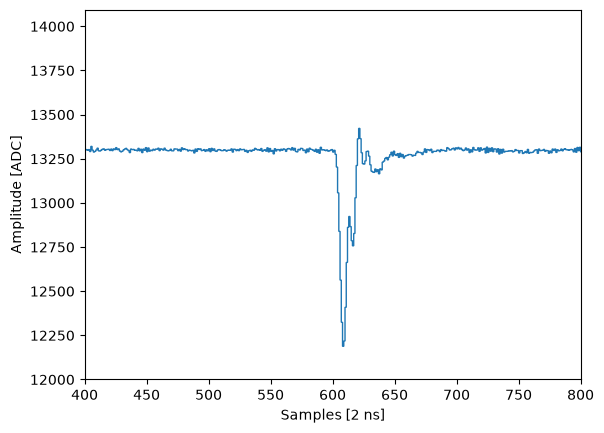

In [39]:
rr_index = 19
plt.stairs(
    raw_records[rr_index]['data'],
    np.arange(raw_records[rr_index]['length'] + 1)
)
plt.xlim(400, 800)
plt.ylim(12000, None)
plt.xlabel('Samples [2 ns]')
plt.ylabel('Amplitude [ADC]')

The good thing about strax is that we only had to replace the DAQReader, so we can use all other plugins right away. We only have to adjust some of their settings to our data:

In [40]:
st.show_config('records')

,option,default,current,applies_to,help
0,n_tpc_pmts,detector://n_tpc_pmts,<OMITTED>,"(records, pulse_counts)",Total number of TPC PMT channels.
1,baseline_samples,40,<OMITTED>,"(records, pulse_counts)",Number of samples at the start of each pulse u...
2,hit_min_amplitude,15,<OMITTED>,"(records, pulse_counts)",Minimum hit amplitude in ADC counts above base...
3,save_outside_hits,"(3, 20)",<OMITTED>,"(records, pulse_counts)","(left, right) samples to preserve on each side..."
4,check_raw_record_overlaps,True,<OMITTED>,"(records, pulse_counts)",Raise if any two pulses in the same channel ov...
5,allow_sloppy_chunking,False,<OMITTED>,"(records, pulse_counts)",Accept incorrectly chunked pulse fragments by ...
6,daq_input_dir,<OMITTED>,/mnt/d/XLZD/mymodules/abstrax/test_data/dummy_...,"(raw_records,)",Path to files of current run.


In [ ]:
st.set_config(
    {'hit_min_amplitude': 60, 
     'save_outside_hits': (10, 40)
     }
)

records = st.get_array('000000', 'records', selection='channel == 0')

Text(0, 0.5, 'Amplitude [ADC]')

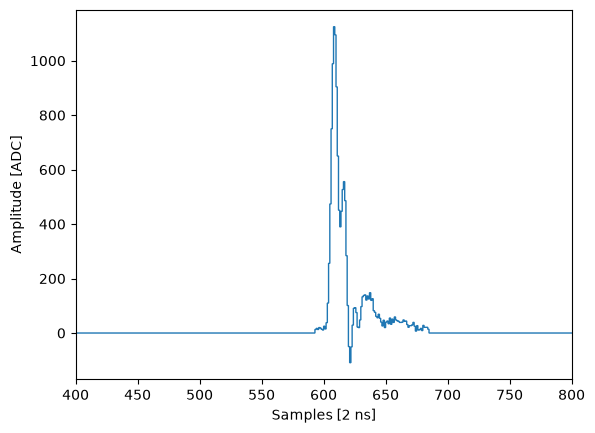

In [45]:
rr_index = 19
plt.stairs(
    records[rr_index]['data'],
    np.arange(records[rr_index]['length'] + 1)
)
plt.xlim(400, 800)
plt.xlabel('Samples [2 ns]')
plt.ylabel('Amplitude [ADC]')

As good practice, we should also write a run metadata file, which we can later find in our database. See section 5.2 of the first tutorial for how run metadata files can be defined. For your processing framework, I recommend writing a short executable script that processes your run and writes the metadata file right away.

**Enjoy working with strax!**